# Plot the steady state spectrum for single configuration

In [2]:
import numpy as np
import os
import astropy.units as u
import astropy.constants as const
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import h5py

import json

from synch_emission_functions import f_p_0, f_e_0, mp, me, c, ep_ratio

import steady state spectrum properties

In [3]:
fig_dir = "/home/kwatanabe/Projects/cr-bowshocks/figures/emission_revised"
data_dir = "/home/kwatanabe/Projects/cr-bowshocks/crbowshock_analysis_tools/data"
# load the bowshock config
bowshock_config = json.load(open("../../config/bowshock_config.json", "r"))["config"]

In [4]:


# pp_arr = np.logspace(0.8, 4, 200) * u.GeV / c  # energy grid for protons
# pp_arr = (pp_arr / (mp * c)).to_value(
#     u.dimensionless_unscaled
# )  # normalised momentum wrt protons
pp_arr = np.logspace(0, 5, 200)
print(
    f"Minimum & maximum of normalised momentum (protons): {(pp_arr.min() * mp * c**2).to(u.GeV):.5e}, {(pp_arr.max() * mp * c**2).to(u.GeV):.5e}"
)

# pe_arr = np.logspace(-5, 4, 200) * u.GeV / c # energy grid for electrons
# pe_arr = (pe_arr / (me * c)).to_value(
#     u.dimensionless_unscaled
# )  # normalised momentum wrt protons
pe_arr = np.logspace(2, 7, 200)
print(
    f"Minimum & maximum of normalised momentum (electrons): {(pe_arr.min() * me * c**2).to(u.GeV):.5f}, {(pe_arr.max() * me * c**2).to(u.GeV):.5e}"
)
Kep, pp0, pe0 = (
    ep_ratio()
)  # get the normalisation for the electron spectrum based on the proton spectrum at 10 GeV, and the corresponding momenta

Minimum & maximum of normalised momentum (protons): 9.38272e-01 GeV, 9.38272e+04 GeV
Minimum & maximum of normalised momentum (electrons): 0.05110 GeV, 5.10999e+03 GeV
ep ratio parameters: 0.01, 10.658, 19569.512


In [5]:
alpha_inj_p = 4.2
alpha_inj_e = 4.2

dens_val = 1e-25 * (u.g / u.cm**3)
mag_val = 1 * u.uG
vel_val = 100 * u.km/u.s
r_pos = 5 * u.pc

For each simulation, calculate the steady state spectrum for protons & electrons

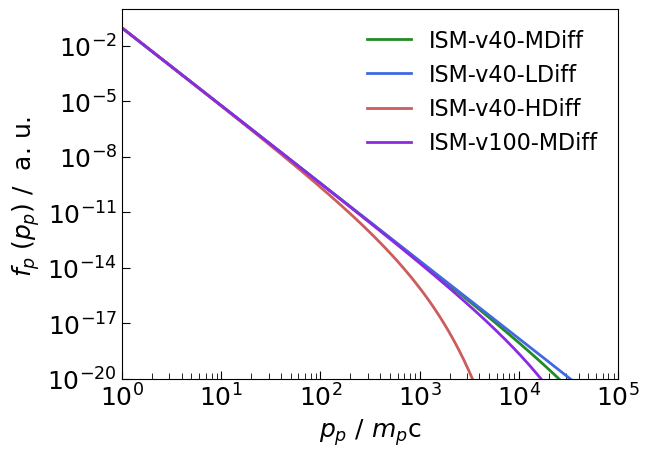

In [14]:
fig, ax = plt.subplots()

sim_names = ["ISM-v40-MDiff", "ISM-v40-LDiff", "ISM-v40-HDiff", "ISM-v100-MDiff"]

for sim_name in sim_names:
    sim_dir = bowshock_config[sim_name]["sim_dir"]

    fp0 = f_p_0(
        alpha_inj_p,
        pp_arr,
        dens_val,
        vel_val,
        pmax=bowshock_config[sim_name]["pmax_prot"],
        vstar=bowshock_config[sim_name]["vstar"] * (u.km/u.s)
    )
    fp0 /= np.trapz(4 * np.pi * pp_arr**2 * fp0, x=pp_arr)

    ax.loglog(pp_arr, fp0, ls="-", color=bowshock_config[sim_name]['color'], lw=2.0, label=bowshock_config[sim_name]['label'])

ax.set_xlabel(r"$p_p$ / $m_p$c", fontsize=18)
ax.set_ylabel(r"$f_p \; (p_p)$ /  a. u. ", fontsize=18)
# ax.set_ylabel(r"$\hat{f} \; (p)$ / a. u. ", fontsize=18)

ax.set_xlim(1, 1e5)
ax.set_ylim(ymin=1e-20, ymax=1)

ax.tick_params(axis='both', direction="in", which='major', size=6, labelsize=18)
ax.tick_params(axis='both', direction="in", which='minor', size=4, labelsize=16)

ax.legend(loc="upper right", prop={"size":16}, frameon=False)
# leg1 = ax.legend(handles=alpha_inj_handles, loc="upper right", prop={"size":14}, bbox_to_anchor=[1.38, 1.02])
# ax.add_artist(leg1)
# ax.legend(handles=alpha_e_handles, loc="lower right", prop={"size":14}, bbox_to_anchor=[1.38, -0.02])

# ax.set_title(fr"$\alpha_{{inj}}$ = {alpha_inj_p}, $\rho$ = $10^{{{np.log10(dens_val.value):.0f}}}$ g cm$^{{-3}}$, $v$ = {vel_val.value:.0f} km s$^{{-1}}$", fontsize=16)

fig.savefig(f"{fig_dir}/steady_state_spectra_proton.pdf", dpi=150, bbox_inches='tight')

NOw calculate for electrons

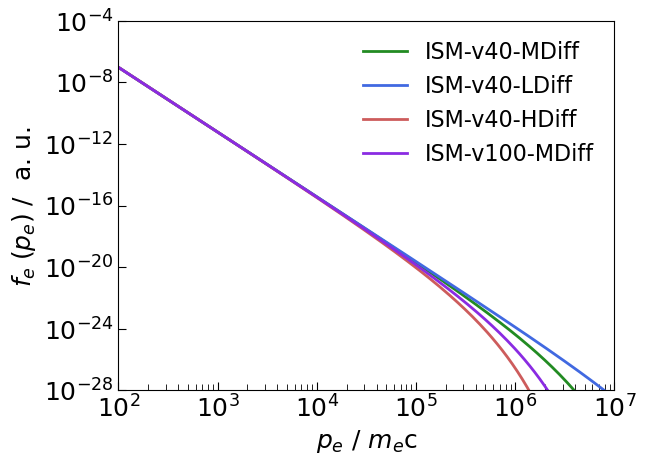

In [13]:
fig, ax = plt.subplots()

sim_names = ["ISM-v40-MDiff", "ISM-v40-LDiff", "ISM-v40-HDiff", "ISM-v100-MDiff"]

for sim_name in sim_names:
    sim_dir = bowshock_config[sim_name]["sim_dir"]

    fe0 = f_e_0(
        alpha_inj_e,
        pe_arr,
        dens_val,
        mag_val,
        Tstar=1e4 * u.K,  # assumed based on stellar track from Ekstrom+2012
        vel=vel_val,
        pmax=bowshock_config[sim_name]["pmax_electr"],
        vstar=bowshock_config[sim_name]["vstar"] * (u.km/u.s),
        r_pos=r_pos
    )

    fe = (
        Kep
        * f_p_0(
            alpha_inj_p,
            pp0,
            dens_val,
            vel_val,
            pmax=bowshock_config[sim_name]["pmax_prot"],
            vstar=bowshock_config[sim_name]["vstar"] * (u.km/u.s)
        )
        / f_e_0(
            alpha_inj_e,
            pe0,
            dens_val,
            mag_val,
            Tstar=1e4 * u.K,
            vel=vel_val,
            pmax=bowshock_config[sim_name]["pmax_electr"],
            vstar=bowshock_config[sim_name]["vstar"] * (u.km/u.s),
            r_pos=r_pos
        )
        * fe0
    )
    fe /= np.trapz(4 * np.pi * pe_arr**2 * fe, x=pe_arr)

    ax.loglog(pe_arr, fe, ls="-", color=bowshock_config[sim_name]['color'], lw=2.0, label=bowshock_config[sim_name]['label'])

ax.set_xlabel(r"$p_e$ / $m_e$c", fontsize=18)
ax.set_ylabel(r"$f_e \; (p_e)$ /  a. u. ", fontsize=18)
# ax.set_ylabel(r"$\hat{f} \; (p)$ / a. u. ", fontsize=18)

ax.set_xlim(1e2, 1e7)
ax.set_ylim(ymin=1e-28, ymax=1e-4)

ax.tick_params(axis='both', direction="in", which='major', size=6, labelsize=18)
ax.tick_params(axis='both', direction="in", which='minor', size=4, labelsize=16)

ax.legend(loc="upper right", prop={"size":16}, frameon=False)
# leg1 = ax.legend(handles=alpha_inj_handles, loc="upper right", prop={"size":14}, bbox_to_anchor=[1.38, 1.02])
# ax.add_artist(leg1)
# ax.legend(handles=alpha_e_handles, loc="lower right", prop={"size":14}, bbox_to_anchor=[1.38, -0.02])

# ax.set_title(fr"$\alpha_{{inj}}$ = {alpha_inj_e}, $\rho$ = $10^{{{np.log10(dens_val.value):.0f}}}$ g cm$^{{-3}}$, $v$ = {vel_val.value:.0f} km s$^{{-1}}$, $B$ = {mag_val.value:.0f} $\mu$G", fontsize=16)

fig.savefig(f"{fig_dir}/steady_state_spectra_electron.pdf", dpi=150, bbox_inches='tight')